# Khám Phá Dữ Liệu Tiêu Thụ Điện Hộ Gia Đình (Exploratory Data Analysis)

**Bài tập lớn môn học Machine Learning**  
**Tập dữ liệu**: UCI Individual Household Electric Power Consumption (Dataset ID: 235)  
**Thời gian đo đạc**: 16/12/2006 đến 26/11/2010 (2.075.259 phút đo đạc)

> **Lưu ý phương pháp luận**: Phân tích khám phá toàn bộ tập dữ liệu (Full-dataset EDA) ở đây mang tính chất mô tả hậu nghiệm (descriptive posthoc), phục vụ mục đích hiểu các đặc tính thống kê cơ bản của chuỗi thời gian năng lượng, hoàn toàn không được sử dụng để tinh chỉnh siêu tham số hay rò rỉ thông tin sang việc đánh giá mô hình trên tập Test.

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Hoạt động độc lập dù chạy từ thư mục gốc hay thư mục notebooks/
data_dir = Path('data/processed') if Path('data/processed').exists() else Path('../data/processed')
parquet_path = data_dir / 'hourly_power.parquet'
stats_path = data_dir / 'data_stats.json'

df = pd.read_parquet(parquet_path)
with open(stats_path, 'r', encoding='utf-8') as f:
    data_stats = json.load(f)

print(f'Tong so khoang gio: {len(df):,}')
print(f'So gio du 60 phut hop le: {data_stats["complete_target_hours"]:,} ({data_stats["valid_target_ratio"]:.2%})')
print(f'So gio khong hop le: {data_stats["incomplete_target_hours"]:,}')

Tong so khoang gio: 34,589
So gio du 60 phut hop le: 34,085 (98.54%)
So gio khong hop le: 504


## 1. Thống Kê Mô Tả Công Suất Tác Dụng (Active Power Distribution)

Phụ tải điện hộ gia đình có phân phối lệch phải mạnh (Right-skewed), tập trung chủ yếu ở mức phụ tải nền thấp (0,3 - 1,0 kW) và xuất hiện các đỉnh xung điện ngắn hạn khi bật các thiết bị công suất lớn.

In [2]:
valid_power = df['target'].dropna()
summary = valid_power.describe(percentiles=[0.25, 0.5, 0.75, 0.90])
print('=== THONG KE MO TA CONG SUAT (kW) ===')
print(summary.to_string())

=== THONG KE MO TA CONG SUAT (kW) ===
count    34085.000000
mean         1.090361
std          0.896738
min          0.124000
25%          0.341700
50%          0.801833
75%          1.578133
90%          2.343667
max          6.560533


- **Giá trị trung vị (Median)**: `0.8018 kW`
- **Giá trị trung bình (Mean)**: `1.0904 kW`
- **Phân vị 90 (P90 High-load)**: `2.3437 kW`

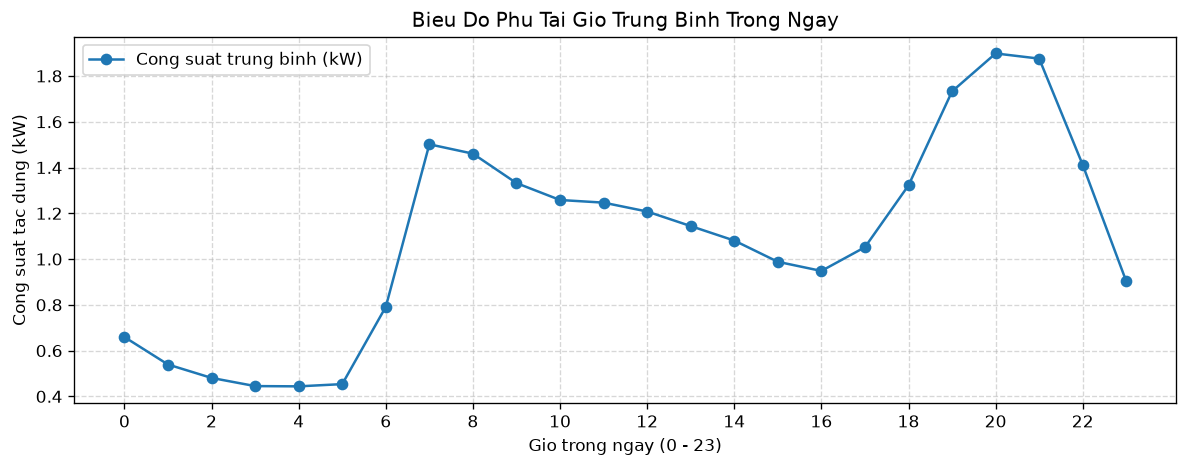

In [3]:
# Ve bieu do phu tai ngay dien hinh (Diurnal Pattern)
hours = df.index.hour
hourly_mean = df.groupby(hours)['raw_active_power'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hourly_mean.index, hourly_mean.values, marker='o', color='#1f77b4', label='Cong suat trung binh (kW)')
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Gio trong ngay (0 - 23)')
ax.set_ylabel('Cong suat tac dung (kW)')
ax.set_title('Bieu Do Phu Tai Gio Trung Binh Trong Ngay')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

## 2. Kết Quả Quan Sát Chu Kỳ Từ Dữ Liệu Thực Tế

- **Khung giờ có phụ tải thấp nhất**: Giờ `04:00` đạt mức trung bình `0.4439 kW`.
- **Khung giờ có phụ tải cao nhất**: Giờ `20:00` đạt mức trung bình `1.8984 kW`.
- **Mức phụ tải trung bình ngày trong tuần (Thứ 2 - Thứ 6)**: `1.0345 kW`.
- **Mức phụ tải trung bình cuối tuần (Thứ 7 - Chủ Nhật)**: `1.2325 kW`.

Sự chênh lệch này cho thấy tính chu kỳ 24 giờ và tính chất ngày trong tuần là các tín hiệu quan trọng cần đưa vào mô hình học máy.